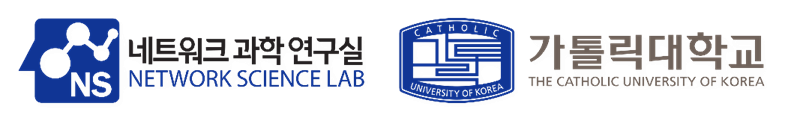

# Week 11: Generative Graph Models & Diffusion

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W11/SampleCode_11.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### The idea in two sentences

* A **generative model** learns what a family of graphs looks like and can then **create new graphs** from that family (new molecules, new social networks, ...).
* We look at two representative models and train both on the **same** family of graphs:

| | **GraphVAE** (Simonovsky & Komodakis, 2018) | **Graph diffusion** (DiGress-style, Vignac et al., 2023) |
|---|---|---|
| Generates | whole new (small) graphs | whole new graphs |
| How | encode a graph into **one** random vector $z$, an MLP decodes $z$ into **all edge probabilities at once** | start from a random graph, remove the noise **step by step** |
| Hard part | the output has a node order, the input does not: needs **graph matching** | needs many denoising steps |

Section 2 builds a dataset of **graphs with two communities**. Part A trains a GraphVAE on it and draws the graphs it generates. Part B trains a small diffusion model on the same graphs, we watch it create a graph from pure noise, and at the end we compare both models.

## 1. Setup

In [1]:
# @title Install dependencies (Colab)
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric"])

In [2]:
# @title Imports and colors
import math
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # Optional PyG extension notices.

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib import animation
from IPython.display import HTML

import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment
from torch_geometric.nn import DenseGCNConv

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)

# One color per role, reused in every figure.
COLORS = {"real": "#2a78d6", "graphvae": "#8a5cd6", "diffusion": "#1baf7a", "random": "#9a9a9a"}
GROUP_COLORS = np.array(["#2a78d6", "#eda100", "#e87ba4", "#4a3aa7"])   # node color = community
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
                     "animation.embed_limit": 50})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.11.0+cu128 | device: cuda


## 2. Data: graphs with two communities

Each graph has 16 nodes in **two groups of 8**. Inside a group, each pair is connected with probability 0.7; the two groups are joined by just 2 edges (similar to the *Community-small* benchmark). Node order is shuffled, so a model has to discover the groups by itself.

A graph with $n$ nodes is stored as its $n \times n$ **adjacency matrix** $A$ ($A_{ij}=1$ if nodes $i$ and $j$ are connected).

In [3]:
N_NODES, P_IN, N_BETWEEN = 16, 0.7, 2

def community_graph(rng):
    """Two groups of 8 nodes (dense inside, 2 edges between). Returns adjacency and group labels."""
    labels = np.repeat([0, 1], N_NODES // 2)
    same = labels[:, None] == labels[None, :]
    A = (rng.random((N_NODES, N_NODES)) < P_IN) & same           # dense inside each group
    for _ in range(N_BETWEEN):                                     # a few edges between the groups
        A[rng.integers(8), 8 + rng.integers(8)] = True
    A = np.triu(A, 1)
    A = (A | A.T).astype(np.float32)
    perm = rng.permutation(N_NODES)                                # hide the order
    return A[perm][:, perm], labels[perm]

rng = np.random.default_rng(SEED)
dataset = [community_graph(rng) for _ in range(1000)]
A0 = torch.tensor(np.stack([A for A, _ in dataset]))              # [1000, 16, 16]
P = (A0.sum() / (len(A0) * N_NODES * (N_NODES - 1))).item()       # average edge density
print(f"{len(A0)} graphs, {N_NODES} nodes each, average {A0.sum().item() / 2 / len(A0):.1f} edges, density p = {P:.2f}")

1000 graphs, 16 nodes each, average 41.1 edges, density p = 0.34


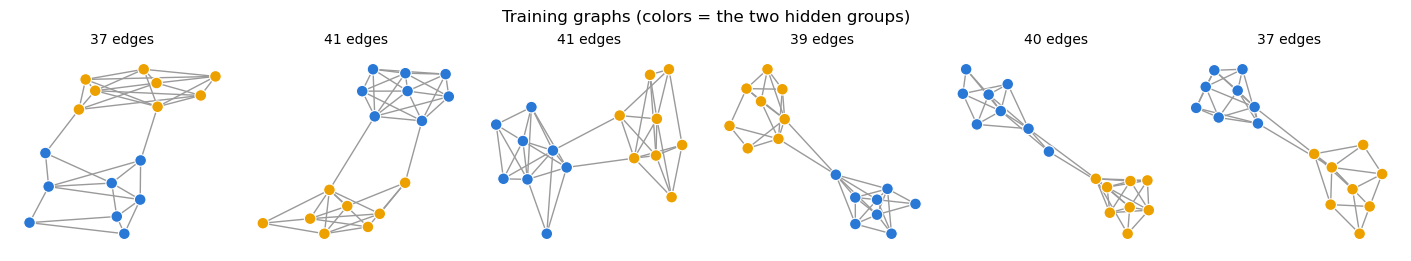

In [4]:
# @title Helpers: draw a graph, count edges inside / between groups
def layout(A):
    return nx.spring_layout(nx.from_numpy_array(np.asarray(A)), seed=SEED)

def draw_graph(ax, A, pos=None, labels=None, title=None):
    A = np.asarray(A)
    G = nx.from_numpy_array(A)
    pos = layout(A) if pos is None else pos
    colors = "#7a7a7a" if labels is None else GROUP_COLORS[np.asarray(labels) % len(GROUP_COLORS)]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9a9a", width=1)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=70, edgecolors="white", linewidths=0.8)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def draw_matrix(ax, M, labels, title=None):
    """Adjacency / edge-probability matrix with nodes sorted by group (red lines = group borders)."""
    labels = np.asarray(labels)
    order = np.argsort(labels, kind="stable")
    ax.imshow(np.asarray(M)[np.ix_(order, order)], cmap="Greys", vmin=0, vmax=1)
    for cut in np.flatnonzero(np.diff(labels[order])) + 0.5:
        ax.axhline(cut, color="#e34948", lw=1)
        ax.axvline(cut, color="#e34948", lw=1)
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)

def find_groups(A):
    """Community label of every node, found by greedy modularity maximization."""
    groups = nx.community.greedy_modularity_communities(nx.from_numpy_array(np.asarray(A)))
    labels = np.zeros(len(A), dtype=int)
    for k, g in enumerate(groups):
        labels[list(g)] = k
    return labels

def inside_between(A, labels):
    same = np.asarray(labels)[:, None] == np.asarray(labels)[None, :]
    A = np.asarray(A)
    return (A * same).sum() / 2, (A * ~same).sum() / 2

fig, axes = plt.subplots(1, 6, figsize=(14, 2.5), constrained_layout=True)
for ax, (A, lab) in zip(axes, dataset):
    draw_graph(ax, A, labels=lab, title=f"{int(A.sum() // 2)} edges")
fig.suptitle("Training graphs (colors = the two hidden groups)")
plt.show()

## 3. Part A: GraphVAE, a whole graph from one vector

**GraphVAE** is a variational auto-encoder whose latent vector describes a **whole graph** (not one node):

1. **Encoder**: a 2-layer GCN computes node embeddings, which are averaged into one graph vector. From it we get a mean $\mu$ and a spread $\sigma$.
2. **Sampling**: $z = \mu + \sigma \cdot \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, I)$. One small vector ($8$ numbers here) per graph.
3. **Decoder**: an MLP maps $z$ to an $n \times n$ matrix of edge probabilities $\hat P$ **in one shot**, $\;\hat P_{ab} = P(\text{edge between output slots } a \text{ and } b)$.

To **generate** a new graph we skip the encoder: draw $z \sim \mathcal{N}(0, I)$, decode it into $\hat P$, and sample every edge with its probability.

Our graphs have no node features, so each node starts with two numbers that do not depend on node order: its **degree** and its **number of triangles**.

In [5]:
def node_features(A):
    """Input features of every node: its degree and its number of triangles (the graphs have no node features)."""
    degree = A.sum(-1, keepdim=True)
    triangles = torch.diagonal(A @ A @ A, dim1=-2, dim2=-1).unsqueeze(-1) / 2
    return torch.cat([degree, triangles], dim=-1) / N_NODES

class GraphVAE(nn.Module):
    def __init__(self, n=N_NODES, hidden=64, z_dim=8):
        super().__init__()
        self.n, self.z_dim = n, z_dim
        self.gcn1, self.gcn2 = DenseGCNConv(2, hidden), DenseGCNConv(hidden, hidden)
        self.lin_mu, self.lin_logstd = nn.Linear(hidden, z_dim), nn.Linear(hidden, z_dim)
        self.decoder = nn.Sequential(nn.Linear(z_dim, 128), nn.ReLU(),
                                     nn.Linear(128, 256), nn.ReLU(),
                                     nn.Linear(256, n * n))

    def encode(self, A):                                    # A: [batch, n, n] -> one (mu, log sigma) per GRAPH
        h = self.gcn1(node_features(A), A).relu()
        h = self.gcn2(h, A).relu()
        g = h.mean(dim=1)                                   # pool all nodes into one graph vector
        return self.lin_mu(g), self.lin_logstd(g).clamp(max=10)

    def decode(self, z):                                    # z: [batch, z_dim] -> edge logits [batch, n, n]
        logits = self.decoder(z).view(-1, self.n, self.n)
        return (logits + logits.transpose(1, 2)) / 2        # edge a-b = edge b-a

def sym_bernoulli(prob):
    """Sample a symmetric 0/1 adjacency matrix (no self-loops) from edge probabilities."""
    upper = torch.bernoulli(prob).triu(1)
    return upper + upper.transpose(-1, -2)

### 3.1 The catch: graph matching

The decoder writes its output into **fixed slots** $1, \dots, n$, but the input graph's nodes come in a **random order**. Before we can compare $\hat P$ with the real adjacency matrix $A$, we must decide **which real node goes into which slot**. Comparing $A_{ij}$ with $\hat P_{ij}$ directly would punish the model for a mere renaming of the nodes.

GraphVAE solves this in two steps for every training graph:

1. **Max-pooling graph matching** (Cho et al., 2014): a score $X_{ia}$ of how well real node $i$ fits slot $a$. It is refined a few times with "my neighbors should fit the neighbors of my slot":
$$X_{ia} \;\leftarrow\; X_{ia} + \sum_{j \in \mathcal{N}(i)} \max_{b}\; X_{jb}\, \hat P_{ab}$$
2. **Hungarian algorithm**: turn the scores into the best **one-to-one** assignment of nodes to slots.

Then we reorder $A$ into the slot order and use the usual VAE loss:

$$\mathcal{L} = \underbrace{\text{BCE}\big(\hat P,\ A_{\text{reordered}}\big)}_{\text{rebuild the graph}} \;+\; \underbrace{\mathrm{KL}\big(\mathcal{N}(\mu,\sigma^2)\ \|\ \mathcal{N}(0,I)\big)}_{\text{keep } z \text{ close to a standard normal}}$$

The matching step costs $O(n^4)$ per graph, which is why GraphVAE only works for **small graphs** (the paper uses molecules with at most 38 atoms).

In [6]:
@torch.no_grad()
def match(A, P_hat, iters=30):
    """Which real node goes into which output slot? Max-pooling graph matching + Hungarian algorithm.
    Returns perm with perm[b, a] = the node of graph b that is placed in output slot a."""
    B, n, _ = A.shape
    P_hat = P_hat * (1 - torch.eye(n, device=A.device))       # ignore self-loops
    X = torch.full((B, n, n), 1.0 / n, device=A.device)       # X[b, i, a] = how well node i fits slot a
    for _ in range(iters):
        best = (X[:, :, None, :] * P_hat[:, None, :, :]).amax(-1)   # best[j, a] = max_b X[j, b] * P_hat[a, b]
        X = X + A @ best                                            # sum over the neighbors j of i
        X = X / X.flatten(1).norm(dim=1).view(B, 1, 1)
    perm = np.empty((B, n), dtype=int)
    for b, x in enumerate(X.cpu().numpy()):
        node, slot = linear_sum_assignment(-x)                      # best one-to-one assignment
        perm[b, slot] = node
    return torch.tensor(perm, device=A.device)

def reorder(A, perm):
    """Put the nodes of every graph into slot order: A[b][perm[b]][:, perm[b]]."""
    b = torch.arange(len(A), device=A.device)[:, None, None]
    return A[b, perm[:, :, None], perm[:, None, :]]

### 3.2 Training

In [7]:
torch.manual_seed(SEED)
gvae = GraphVAE().to(DEVICE)
gvae_opt = torch.optim.Adam(gvae.parameters(), lr=1e-3)
A0_dev = A0.to(DEVICE)
off_diag = 1 - torch.eye(N_NODES, device=DEVICE)                   # no self-loops: ignore the diagonal

for it in range(1, 3001):
    A = A0_dev[torch.randint(len(A0_dev), (64,))]
    mu, logstd = gvae.encode(A)
    z = mu + torch.randn_like(mu) * logstd.exp()                    # one random vector per graph
    logits = gvae.decode(z)
    A_target = reorder(A, match(A, torch.sigmoid(logits)))          # real graph, put into the decoder's slot order
    rec = F.binary_cross_entropy_with_logits(logits, A_target, weight=off_diag, reduction="sum") / len(A)
    kl = -0.5 * (1 + 2 * logstd - mu ** 2 - (2 * logstd).exp()).sum(1).mean()
    loss = rec + kl
    gvae_opt.zero_grad()
    loss.backward()
    gvae_opt.step()
    if it % 500 == 0:
        print(f"iteration {it}: reconstruction {rec.item():.1f}   KL {kl.item():.2f}")

iteration 500: reconstruction 121.9   KL 0.01


iteration 1000: reconstruction 109.0   KL 0.01


iteration 1500: reconstruction 108.2   KL 0.02


iteration 2000: reconstruction 106.4   KL 0.09


iteration 2500: reconstruction 102.4   KL 0.42


iteration 3000: reconstruction 101.0   KL 0.70


### 3.3 What comes out of GraphVAE?

**Reconstruction.** We encode three *new* community graphs (never seen in training), decode them, and sample a graph from $\hat P$. The matching tells us which real node each slot stands for, so the reconstruction is drawn with the **same node positions and colors** as the input.

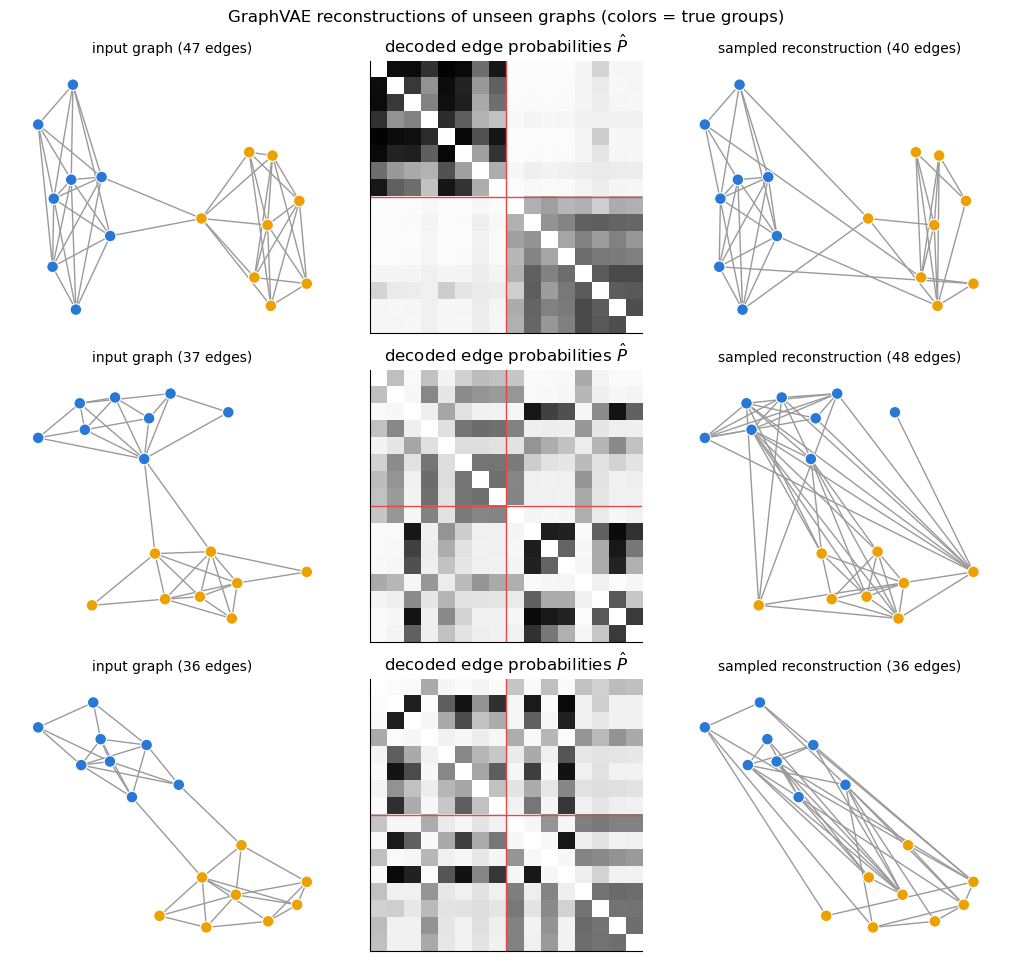

In [8]:
# @title Plot: input graph -> edge probabilities -> sampled reconstruction
examples = [community_graph(np.random.default_rng(SEED + 1000 + i)) for i in range(3)]
A_ex = torch.tensor(np.stack([A for A, _ in examples]), device=DEVICE)
torch.manual_seed(SEED)
with torch.no_grad():
    gvae.eval()
    P_rec = torch.sigmoid(gvae.decode(gvae.encode(A_ex)[0])) * off_diag   # in eval mode z = mu
    perm = match(A_ex, P_rec).cpu().numpy()
    A_rec = sym_bernoulli(P_rec).cpu().numpy()
P_rec = P_rec.cpu().numpy()

fig, axes = plt.subplots(3, 3, figsize=(10, 9.5), constrained_layout=True)
for r, (A, lab) in enumerate(examples):
    pos = layout(A)
    slot_lab = lab[perm[r]]                                    # group of the real node placed in each slot
    slot_pos = {a: pos[perm[r, a]] for a in range(N_NODES)}    # ... and its position
    draw_graph(axes[r, 0], A, pos, lab, title=f"input graph ({int(A.sum() // 2)} edges)")
    draw_matrix(axes[r, 1], P_rec[r], slot_lab, title=r"decoded edge probabilities $\hat P$")
    draw_graph(axes[r, 2], A_rec[r], slot_pos, slot_lab,
               title=f"sampled reconstruction ({int(A_rec[r].sum() // 2)} edges)")
fig.suptitle("GraphVAE reconstructions of unseen graphs (colors = true groups)")
plt.show()

**Generation.** Now the real test: draw $z \sim \mathcal{N}(0, I)$, decode, and sample. No input graph is involved. Top row: the decoded edge probabilities $\hat P$ (slots sorted by the communities found in the sampled graph). Bottom row: the generated graphs, colored by the communities found in them.

In [9]:
@torch.no_grad()
def gvae_generate(num):
    gvae.eval()
    z = torch.randn(num, gvae.z_dim, device=DEVICE)               # z ~ N(0, I): no encoder needed
    P_hat = torch.sigmoid(gvae.decode(z)) * off_diag              # all edge probabilities at once
    return P_hat.cpu(), sym_bernoulli(P_hat).cpu()                # every edge sampled independently

torch.manual_seed(SEED)
gvae_probs, gvae_generated = gvae_generate(200)
print(f"generated {len(gvae_generated)} graphs, average {gvae_generated.sum().item() / 2 / len(gvae_generated):.1f} edges")

generated 200 graphs, average 40.4 edges


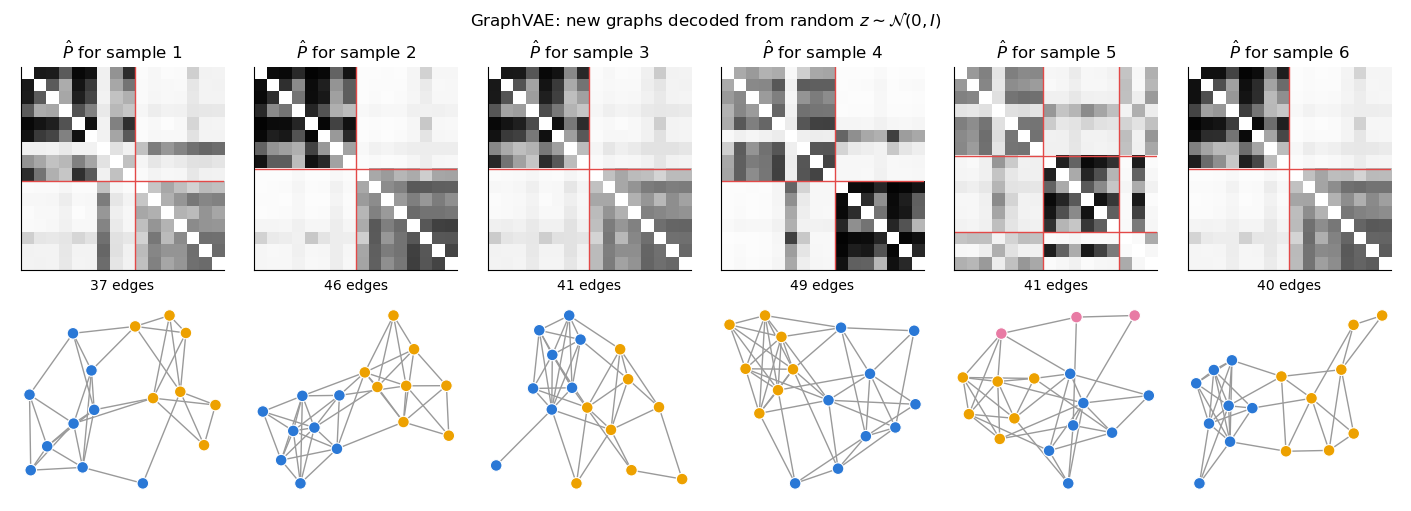

In [10]:
# @title Plot: new graphs generated by GraphVAE
fig, axes = plt.subplots(2, 6, figsize=(14, 5), constrained_layout=True)
for c in range(6):
    A = gvae_generated[c].numpy()
    lab = find_groups(A)
    draw_matrix(axes[0, c], gvae_probs[c], lab, title=r"$\hat P$" + f" for sample {c + 1}")
    draw_graph(axes[1, c], A, labels=lab, title=f"{int(A.sum() // 2)} edges")
fig.suptitle(r"GraphVAE: new graphs decoded from random $z \sim \mathcal{N}(0, I)$")
plt.show()

* **Reconstruction** is only partly faithful (good for the first graph, rough for the others). The KL term pushes $z$ toward $\mathcal{N}(0, I)$, so $z$ keeps little information about the specific input. The decoder mostly outputs its learned template, and the matching places the input's nodes onto it as well as it can.
* The decoder has learned a **template**: 8 slots form one dense block, 8 slots the other. Every random $z$ produces a version of this two-block picture, and sampling it gives a new graph with two communities.
* The blocks are **blurry**: many probabilities sit around 0.3–0.6 instead of near 0 or 1, especially *between* the blocks. Given $z$, every edge is sampled **independently**, so the model cannot say "connect the groups by *exactly* 2 edges". It can only lower the probabilities a bit, which gives extra between-group edges and weaker communities (the numbers are in section 4.4).

**Limits of GraphVAE.** The graph size is **fixed** by the decoder (at most $n$ nodes), the matching step costs $O(n^4)$ per graph, and all edges are decided **in one shot and independently** given $z$. Diffusion removes all three problems: it decides the edges over many small steps, each step looks at the current graph, and it never needs a node order.

## 4. Part B: Graph diffusion, generating graphs step by step

The diffusion idea in one picture:

$$\underbrace{G_0}_{\text{real graph}} \;\xrightarrow{\text{add noise}}\; G_1 \;\rightarrow\; \cdots \;\rightarrow\; \underbrace{G_T}_{\text{random graph}} \qquad\qquad \underbrace{G_T}_{\text{random graph}} \;\xrightarrow{\text{GNN removes noise}}\; \cdots \;\rightarrow\; \underbrace{G_0}_{\text{new graph}}$$

* **Forward** (fixed, no learning): destroy a graph by randomly **flipping a few edges** at each step until nothing is left of it.
* **Reverse** (learned): a GNN learns to undo one step. To **generate**, start from a random graph and apply it $T$ times.

Edges stay 0/1 the whole time (*discrete* diffusion, as in DiGress), so every intermediate step is a real graph that we can draw. Unlike GraphVAE, the denoiser works directly on the graph, so there is **no node order to match**.

> **Note: this is a simplified DiGress, not the full model.** It keeps DiGress's key ideas: discrete edge-flipping noise toward the average density $p$ (marginal noise), a network that predicts the clean graph, and Bayes' rule for each reverse step. But it is much smaller:


### 4.1 Forward process: turning a graph into noise

At step $t$, every node pair **keeps its state** with probability $\alpha_t$; otherwise it is **redrawn at random** (an edge with probability $p$, the average density). After $t$ steps there is a simple closed form:

$$P(\text{edge } i\text{–}j \text{ at step } t) \;=\; \bar\alpha_t \, A^{(0)}_{ij} \;+\; (1-\bar\alpha_t)\, p, \qquad \bar\alpha_t = \alpha_1 \alpha_2 \cdots \alpha_t$$

$\bar\alpha_t$ goes from 1 (the real graph) to 0 at $t=T$ (a fully random graph with the same density, an Erdős–Rényi graph).

In [11]:
STEPS = 50                                                          # T
s = torch.linspace(0, 1, STEPS + 1)
alpha_bar = torch.cos((s + 0.008) / 1.008 * math.pi / 2) ** 2       # cosine schedule (Nichol & Dhariwal, 2021)
alpha_bar = alpha_bar / alpha_bar[0]
alpha_bar[-1] = 0.0                                                 # step T: nothing of the graph is left
alpha = torch.ones(STEPS + 1)
alpha[1:] = alpha_bar[1:] / alpha_bar[:-1]                          # keep probability of each single step

def q_step(A, t):
    """One forward step t-1 -> t: keep each pair with prob alpha_t, else redraw it with density p."""
    return sym_bernoulli(alpha[t] * A + (1 - alpha[t]) * P)

def q_sample(A0, t):
    """Jump straight from step 0 to step t (used for training)."""
    ab = alpha_bar[t].view(-1, 1, 1).to(A0.device)
    return sym_bernoulli(ab * A0 + (1 - ab) * P)

In [12]:
# @title Helper: animate a sequence of graphs
def animate_graphs(frames, steps, labels, pos, reverse=False, every=2, interval=250):
    """Left: graph (fixed node positions). Middle: adjacency sorted by group. Right: edges inside vs between.
    Draws only every `every`-th step to keep the notebook small."""
    order = np.argsort(labels, kind="stable")
    cut = np.sum(labels == labels[order][0]) - 0.5                  # border between the two groups
    counts = np.array([inside_between(A, labels) for A in frames])
    fig, (ax_g, ax_a, ax_c) = plt.subplots(1, 3, figsize=(12, 3.6), dpi=60, constrained_layout=True,
                                           gridspec_kw={"width_ratios": [1, 1, 1.3]})

    def draw(k):
        for ax in (ax_g, ax_a, ax_c):
            ax.clear()
        draw_graph(ax_g, frames[k], pos, labels, title=f"step t = {steps[k]}")
        ax_a.imshow(frames[k][np.ix_(order, order)], cmap="Greys", vmin=0, vmax=1)
        ax_a.axhline(cut, color="#e34948", lw=1)
        ax_a.axvline(cut, color="#e34948", lw=1)
        ax_a.set(title="adjacency (sorted by group)", xticks=[], yticks=[])
        ax_a.grid(False)
        ax_c.plot(steps, counts[:, 0], color=COLORS["real"], lw=2, label="edges inside groups")
        ax_c.plot(steps, counts[:, 1], color="#e34948", lw=2, label="edges between groups")
        ax_c.axvline(steps[k], color="black", lw=1)
        ax_c.set(xlabel="step t", ylabel="number of edges", ylim=(0, counts.max() + 5), xlim=(0, STEPS))
        if reverse:
            ax_c.invert_xaxis()
        ax_c.legend(frameon=False, loc="upper center")

    shown = sorted(set(range(0, len(frames), every)) | {len(frames) - 1})
    anim = animation.FuncAnimation(fig, draw, frames=shown, interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml())

Let's destroy one training graph, one step at a time. Press ▶ (or drag the slider).

In [13]:
torch.manual_seed(SEED)
A_real, labels_real = dataset[0]
frames = [torch.tensor(A_real)]                                    # G_0 = the real graph
for t in range(1, STEPS + 1):
    frames.append(q_step(frames[-1], t))                            # G_{t-1} -> G_t

animate_graphs([f.numpy() for f in frames], list(range(STEPS + 1)), labels_real, layout(A_real))

The two groups slowly dissolve: edges inside the groups disappear, edges between the groups appear, until the graph is just random. The **reverse** direction is what we need a model for.

### 4.2 The denoiser: a GNN that guesses the clean graph

Given a noisy graph $A^{(t)}$ and the step $t$, the network predicts for **every pair** the probability that the edge exists in the **clean** graph, $\hat p_{ij} = P(A^{(0)}_{ij}=1 \mid A^{(t)})$.

To spot the groups, a pair $(i,j)$ should look at **common neighbors**: two nodes with many shared neighbors are probably in the same group. We keep a feature vector $E_{ij}$ for every pair and update it with all **2-step paths** $i \to k \to j$:

$$E_{ij} \;\leftarrow\; E_{ij} + \mathrm{MLP}\Big(E_{ij},\ \tfrac{1}{n}\textstyle\sum_k (W_1 E_{ik}) \odot (W_2 E_{kj})\Big)$$

(this is a *PPGN*-style layer, Maron et al., 2019). Stacking 4 layers lets every pair see paths of up to 16 steps. Renaming the nodes only renames the output, so the model treats graphs as graphs, not as ordered matrices.

In [14]:
class PairLayer(nn.Module):
    """Update every pair (i, j) with all 2-step paths i -> k -> j."""
    def __init__(self, d):
        super().__init__()
        self.w1, self.w2 = nn.Linear(d, d), nn.Linear(d, d)
        self.mlp = nn.Sequential(nn.Linear(2 * d, d), nn.SiLU(), nn.Linear(d, d))
        self.norm = nn.LayerNorm(d)

    def forward(self, E):                                           # E: [batch, n, n, d]
        left = self.w1(E).permute(0, 3, 1, 2)                       # [batch, d, n, n]
        right = self.w2(E).permute(0, 3, 1, 2)
        paths = (left @ right).permute(0, 2, 3, 1) / E.size(1)      # sum over k of E_ik * E_kj
        return self.norm(E + self.mlp(torch.cat([E, paths], dim=-1)))

class Denoiser(nn.Module):
    def __init__(self, d=32, n_layers=4):
        super().__init__()
        self.inp = nn.Linear(3, d)                                  # pair input: [edge in A_t, i == j, t / T]
        self.layers = nn.ModuleList(PairLayer(d) for _ in range(n_layers))
        self.out = nn.Linear(d, 1)

    def forward(self, A_t, t):
        B, n, _ = A_t.shape
        eye = torch.eye(n, device=A_t.device).expand(B, n, n)
        time = (t.float() / STEPS).view(B, 1, 1).expand(B, n, n)
        E = self.inp(torch.stack([A_t, eye, time], dim=-1))
        for layer in self.layers:
            E = layer(E)
        logits = self.out(E).squeeze(-1)
        return (logits + logits.transpose(1, 2)) / 2                # edge i-j = edge j-i

**Training** is simple: take a real graph, pick a random step $t$, add noise with `q_sample`, and ask the model to recover the clean edges (binary cross-entropy).

In [15]:
torch.manual_seed(SEED)
model = Denoiser().to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
BATCH, ITERS = 128, 4000

for it in range(1, ITERS + 1):
    A_clean = A0_dev[torch.randint(len(A0_dev), (BATCH,))]
    t = torch.randint(1, STEPS + 1, (BATCH,))                       # a random noise level per graph
    A_noisy = q_sample(A_clean, t)
    loss = F.binary_cross_entropy_with_logits(model(A_noisy, t.to(DEVICE)), A_clean, weight=off_diag)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if it % 1000 == 0:
        print(f"iteration {it}: loss {loss.item():.3f}")

iteration 1000: loss 0.368


iteration 2000: loss 0.358


iteration 3000: loss 0.379


iteration 4000: loss 0.349


### 4.3 Reverse process: generating a graph from noise

At each step back, the model first guesses the clean graph $\hat p$. Then we move **one small step** toward it with Bayes' rule (the forward process is known exactly):

$$P(A^{(t-1)}_{ij}=1 \mid A^{(t)}) \;=\; \hat p_{ij}\; q\big(A^{(t-1)}_{ij}=1 \mid A^{(t)}, A^{(0)}_{ij}=1\big) \;+\; (1-\hat p_{ij})\; q\big(A^{(t-1)}_{ij}=1 \mid A^{(t)}, A^{(0)}_{ij}=0\big)$$

and sample $A^{(t-1)}$ from it. Small steps let the model **correct itself** along the way instead of committing to everything at once.

In [16]:
def step_back_prob(A_t, p_hat, t):
    """P(edge at step t-1 | A_t), mixing the two cases 'clean edge = 1' and 'clean edge = 0'."""
    a, ab = alpha[t].item(), alpha_bar[t - 1].item()
    like_1 = torch.where(A_t == 1, a + (1 - a) * P, (1 - a) * (1 - P))   # q(A_t | edge at t-1)
    like_0 = torch.where(A_t == 1, (1 - a) * P, 1 - (1 - a) * P)         # q(A_t | no edge at t-1)

    def given_clean(a0):                                                   # Bayes for a known clean value a0
        prior = ab * a0 + (1 - ab) * P                                     # q(edge at t-1 | A_0 = a0)
        return like_1 * prior / (like_1 * prior + like_0 * (1 - prior))

    return p_hat * given_clean(1) + (1 - p_hat) * given_clean(0)

@torch.no_grad()
def generate(num):
    model.eval()
    A = sym_bernoulli(torch.full((num, N_NODES, N_NODES), P, device=DEVICE))   # step T: a random graph
    trajectory = [A.cpu()]
    for t in range(STEPS, 0, -1):
        p_hat = torch.sigmoid(model(A, torch.full((num,), t, device=DEVICE)))  # guess of the clean graph
        A = sym_bernoulli(step_back_prob(A, p_hat, t))                         # one small step back
        trajectory.append(A.cpu())
    return torch.stack(trajectory, dim=1)                                      # [num, T+1, n, n]

torch.manual_seed(SEED)
traj = generate(200)
generated = traj[:, -1]
print(f"generated {len(generated)} graphs, average {generated.sum().item() / 2 / len(generated):.1f} edges")

generated 200 graphs, average 39.7 edges


Now the main event: **watch the model create a new graph from noise**. Node positions and colors come from the *final* graph (its two communities, found afterwards), so you can see each group pull itself together.

In [17]:
A_new = traj[0, -1].numpy()
labels_new = find_groups(A_new)
animate_graphs([A.numpy() for A in traj[0]], list(range(STEPS, -1, -1)), labels_new, layout(A_new), reverse=True)

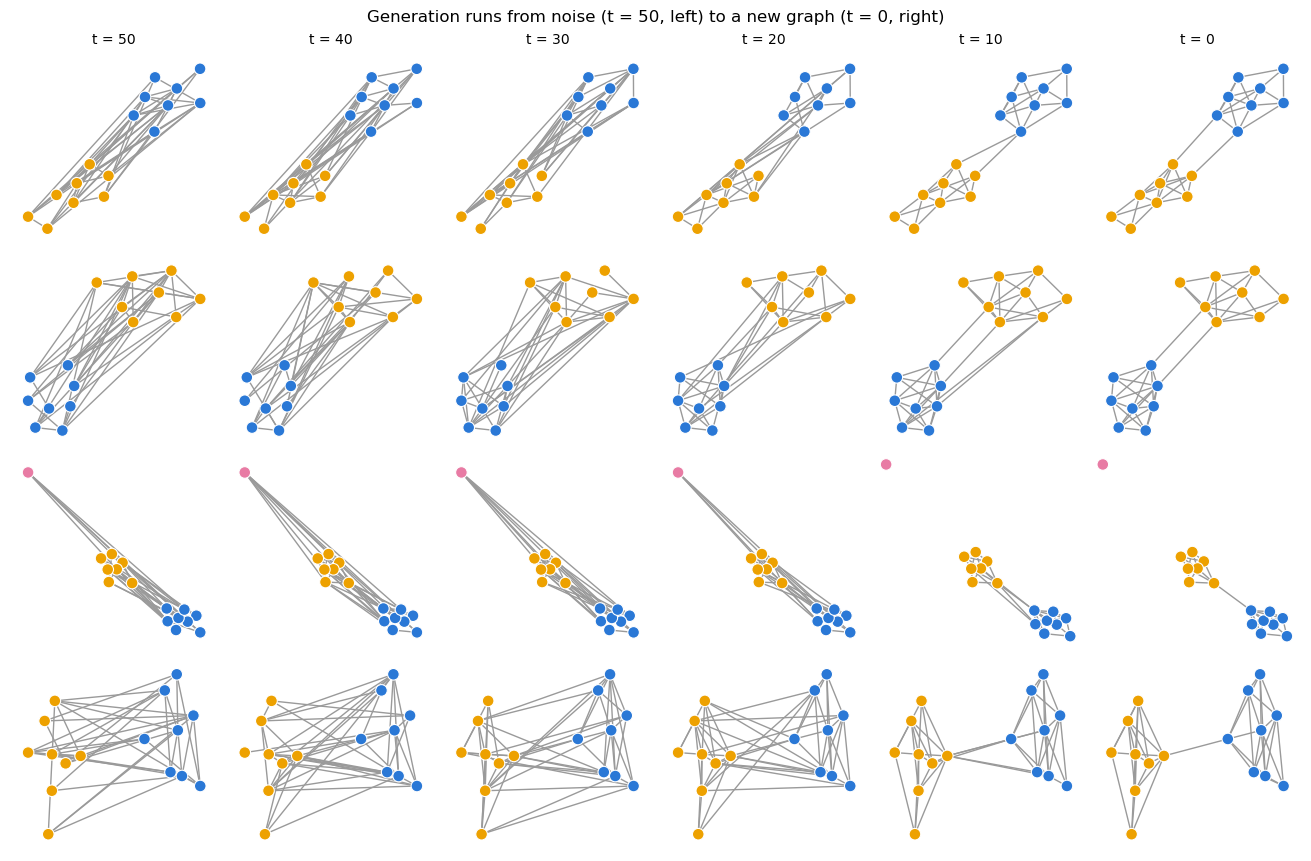

In [18]:
# @title Plot: snapshots of the reverse process for 4 new graphs
SHOW_T = [50, 40, 30, 20, 10, 0]
fig, axes = plt.subplots(4, len(SHOW_T), figsize=(13, 8.5), constrained_layout=True)
for row in range(4):
    final = traj[row, -1].numpy()
    lab, pos = find_groups(final), layout(final)
    for col, t in enumerate(SHOW_T):
        draw_graph(axes[row, col], traj[row, STEPS - t].numpy(), pos, lab,
                   title=f"t = {t}" if row == 0 else None)
fig.suptitle("Generation runs from noise (t = 50, left) to a new graph (t = 0, right)")
plt.show()

Most of the structure appears **between $t \approx 25$ and $t \approx 5$**: at first the model only sees noise and changes little; once a hint of two groups appears, it reinforces it step by step.

### 4.4 Are the new graphs like the training graphs?

We compare 200 **real** graphs, 200 graphs from **GraphVAE**, 200 from the **diffusion** model, and 200 **random** graphs with the same density (the starting noise $G_T$):

* **clustering coefficient**: how often two neighbors of a node are also connected (high inside dense groups),
* **modularity**: how well the graph splits into communities (0 = no community structure).

In [19]:
def graph_stats(As):
    out = {"degree": [], "clustering": [], "modularity": []}
    for A in As:
        G = nx.from_numpy_array(np.asarray(A))
        out["degree"] += [d for _, d in G.degree()]
        out["clustering"].append(nx.average_clustering(G))
        out["modularity"].append(nx.community.modularity(G, nx.community.greedy_modularity_communities(G)))
    return {k: np.array(v) for k, v in out.items()}

real_test = [community_graph(np.random.default_rng(SEED + 1 + i))[0] for i in range(200)]   # fresh real graphs
stats = {"real": graph_stats(real_test),
         "graphvae": graph_stats(gvae_generated.numpy()),
         "diffusion": graph_stats(generated.numpy()),
         "random": graph_stats(traj[:, 0].numpy())}
for name, st in stats.items():
    print(f"{name:9s}  clustering {st['clustering'].mean():.2f}   modularity {st['modularity'].mean():.2f}")

real       clustering 0.64   modularity 0.45
graphvae   clustering 0.53   modularity 0.35
diffusion  clustering 0.60   modularity 0.44
random     clustering 0.34   modularity 0.21


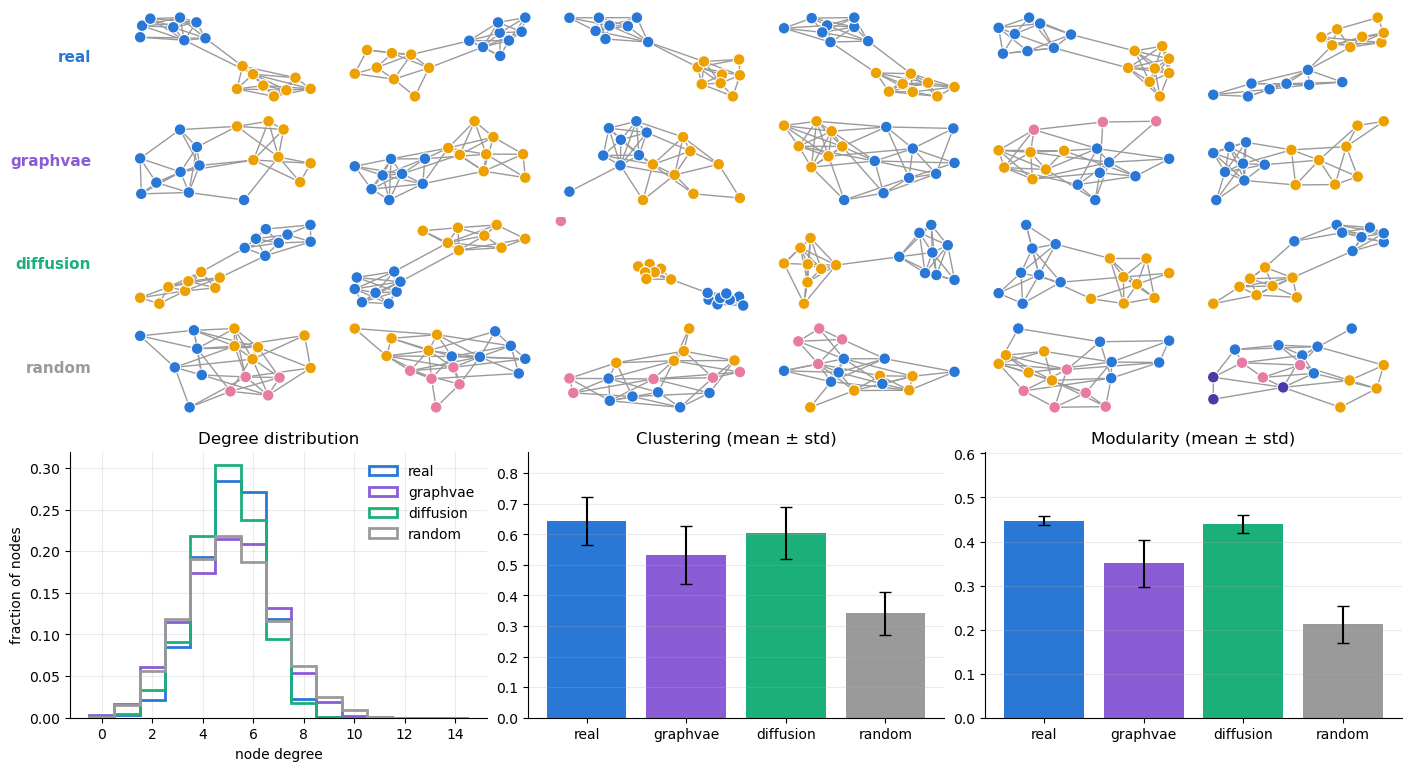

In [20]:
# @title Plot: generated vs real vs random graphs
fig = plt.figure(figsize=(14, 7.6), constrained_layout=True)
top, bottom = fig.subfigures(2, 1, height_ratios=[1.35, 1.1])

axes = top.subplots(4, 6)
rows = [("real", real_test), ("graphvae", gvae_generated.numpy()),
        ("diffusion", generated.numpy()), ("random", traj[:, 0].numpy())]
for r, (name, graphs) in enumerate(rows):
    for c in range(6):
        draw_graph(axes[r, c], graphs[c], labels=find_groups(graphs[c]))
    axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center",
                    fontsize=11, fontweight="bold", color=COLORS[name])

axes = bottom.subplots(1, 3)
bins = np.arange(0, 16) - 0.5
for name, st in stats.items():
    axes[0].hist(st["degree"], bins, density=True, histtype="step", lw=2, color=COLORS[name], label=name)
axes[0].set(xlabel="node degree", ylabel="fraction of nodes", title="Degree distribution")
axes[0].legend(frameon=False)
for ax, key in zip(axes[1:], ["clustering", "modularity"]):
    means = [stats[n][key].mean() for n in stats]
    stds = [stats[n][key].std() for n in stats]
    ax.bar(list(stats), means, yerr=stds, capsize=4, color=[COLORS[n] for n in stats])
    ax.set(title=f"{key.capitalize()} (mean ± std)", ylim=(0, max(means) * 1.35))
    ax.grid(axis="x", visible=False)
plt.show()

* Started from **random graphs** (gray), the diffusion model produces graphs (green) whose degree distribution, clustering and modularity match the **real** ones (blue).
* **GraphVAE** (purple) also learned the two-community idea, but its graphs have more edges between the groups, so their clustering and modularity are lower: that is the price of deciding all edges at once and independently.
* The communities were never given to either model: they learned that "graphs in this family have two dense groups" only from examples, and create **new** graphs with that property.

## 5. Takeaways

* A **generative graph model** learns a family of graphs and samples new members of it.
* **GraphVAE** = GCN encoder + pooling → one random vector $z$ per graph → MLP decoder that outputs **all edge probabilities at once**. Because the output has fixed slots, training needs **graph matching** ($O(n^4)$), so it is limited to small graphs, and edges are independent given $z$.
* **Graph diffusion** = a fixed forward process that turns graphs into noise + a learned GNN denoiser that undoes it **one small step at a time**. It works on the graph directly (no matching) and gets the fine structure right.
* With **discrete** noise (flipping edges), every intermediate step is a valid graph, and the denoiser only has to answer *"is edge $i$–$j$ in the clean graph?"*, a simple classification task.
* The same recipes, with node and edge **types** added (atoms, bond types), are how GraphVAE and **DiGress** generate new molecules.